# Used Car Price Prediction

This notebook explores a used-car listing dataset, applies visible cleaning
rules, and compares five regression models against a median baseline.
Prices are in Turkish lira (TRY). Original category values are kept as recorded.

The aim is to build an understandable workflow rather than optimize every model.
Cleaning thresholds are assumptions to review, not verified facts about the data.
Damage amounts and damage-condition fields are excluded because their quality is unverified.
No row is removed because of its tramer amount.

## 1. Imports and settings

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, Lasso
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

RANDOM_STATE = 42
REFERENCE_YEAR = 2026
TEST_SIZE = 0.20
CV_FOLDS = 5
MODEL_THREADS = 4

DATA_PATH = Path("car_dataset_raw.csv")
OUTPUT_DIR = Path("outputs_car_price_simple")

# Price bounds define the population covered by this project.
MIN_PRICE = 100_000
MAX_PRICE = 100_000_000

pd.set_option('display.float_format', lambda x: '{:,.2f}'.format(x))
pd.set_option("display.precision", 6)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load and inspect the data

Missing values, duplicate rows, and extreme values are inspected before cleaning.

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df_raw.shape[0]:,} rows and {df_raw.shape[1]} columns")
print(f"Exact duplicate rows in the original data: {df_raw.duplicated().sum():,}")
display(df_raw.head())

Dataset shape: 26,533 rows and 26 columns
Exact duplicate rows in the original data: 1,340


,brand,series,model,transmission,fuel_type,body_type,color,drivetrain,vehicle_condition,price_try,year,mileage_km,engine_displacement_cc,engine_power_hp,painted_count,local_painted_count,changed_count,original_count,tramer_tl,hood_damaged,roof_damaged,hood_changed,hood_painted,roof_changed,roof_painted,car_identity
0,Renault,Clio,1.2 Authentique,Düz,LPG & benzin,"Hatchback/5, 5 Koltuk",Gri,Önden Çekiş,İkinci El,395000,2008,"255,000.00","1,149.00",75.00,1,0,6,0,5,0,0,0,0,0,0,Renault Clio 1.2 Authentique
1,Renault,Clio,1.2 Joy,Düz,Benzin,"Hatchback/5, 5 Koltuk",Siyah,Önden Çekiş,İkinci El,444000,2013,"224,000.00","1,149.00",75.00,1,0,0,32,5,0,0,0,0,0,0,Renault Clio 1.2 Joy
2,Renault,Megane,1.6 Dynamique,Düz,Benzin,Sedan,Gri,Önden Çekiş,İkinci El,499000,2004,"258,000.00","1,598.00",115.00,1,0,0,0,5,0,0,0,0,0,0,Renault Megane 1.6 Dynamique
3,Renault,Clio,1.0 TCe Evolution,Otomatik,Benzin,Hatchback/5,Beyaz,Önden Çekiş,İkinci El,935000,2024,"31,150.00",999.00,90.00,1,1,0,8,5,0,0,0,0,0,0,Renault Clio 1.0 TCe Evolution
4,Renault,Megane,1.6 Dynamique,Otomatik,LPG & benzin,Hatchback/3,Füme,Önden Çekiş,İkinci El,439850,2005,"245,000.00","1,598.00",115.00,0,1,0,0,5490,0,0,0,0,0,0,Renault Megane 1.6 Dynamique


In [3]:
column_summary = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isna().sum(),
    "missing_pct": df_raw.isna().mean() * 100,
    "unique_count": df_raw.nunique(),
})
display(column_summary.sort_values("missing_count", ascending=False))

display(df_raw.select_dtypes("number").describe(
    percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
).T)

,dtype,missing_count,missing_pct,unique_count
engine_displacement_cc,float64,527,1.99,231
engine_power_hp,float64,340,1.28,214
drivetrain,str,225,0.85,6
car_identity,str,19,0.07,3502
model,str,19,0.07,2727
transmission,str,8,0.03,3
mileage_km,float64,3,0.01,3491
color,str,3,0.01,24
vehicle_condition,str,3,0.01,4
body_type,str,2,0.01,29


,count,mean,std,min,25%,50%,75%,95%,99%,max
price_try,"26,533.00","1,376,168.68","1,840,090.97","10,000.00","700,000.00","1,190,000.00","1,675,000.00","2,875,000.00","5,977,720.00","189,000,000.00"
year,"26,533.00","2,015.17",8.09,"1,950.00","2,011.00","2,016.00","2,022.00","2,025.00","2,026.00","2,026.00"
mileage_km,"26,530.00","158,217.60","106,592.63",0.00,"73,000.00","145,000.00","227,000.00","345,000.00","440,000.00","2,012,000.00"
engine_displacement_cc,"26,006.00","1,534.26",371.67,796.00,"1,364.00","1,500.00","1,598.00","1,999.00","2,993.00","6,162.00"
engine_power_hp,"26,193.00",129.37,46.50,43.00,100.00,122.00,140.00,204.00,292.00,755.00
painted_count,"26,533.00",0.45,0.77,0.00,0.00,0.00,1.00,1.00,2.00,33.00
local_painted_count,"26,533.00",0.24,0.51,0.00,0.00,0.00,0.00,1.00,1.00,20.00
changed_count,"26,533.00",0.54,0.91,0.00,0.00,0.00,1.00,3.00,4.00,11.00
original_count,"26,533.00",2.95,6.65,0.00,0.00,0.00,3.00,16.00,32.00,88.00
tramer_tl,"26,533.00","1,985,466.98","66,771,975.77",0.00,5.00,5.00,5.00,"40,000.00","44,547,150.56","5,542,952,290.00"


,unique_count,missing_count,top_freq
brand,33,0,Ford
series,400,0,Kuga
model,2727,19,1.0 EcoBoost Style
transmission,3,8,Otomatik
fuel_type,5,0,Benzin
body_type,29,2,SUV
color,24,3,Beyaz
drivetrain,6,225,Önden Çekiş
vehicle_condition,4,3,İkinci El
car_identity,3502,19,Ford Puma 1.0 EcoBoost Style


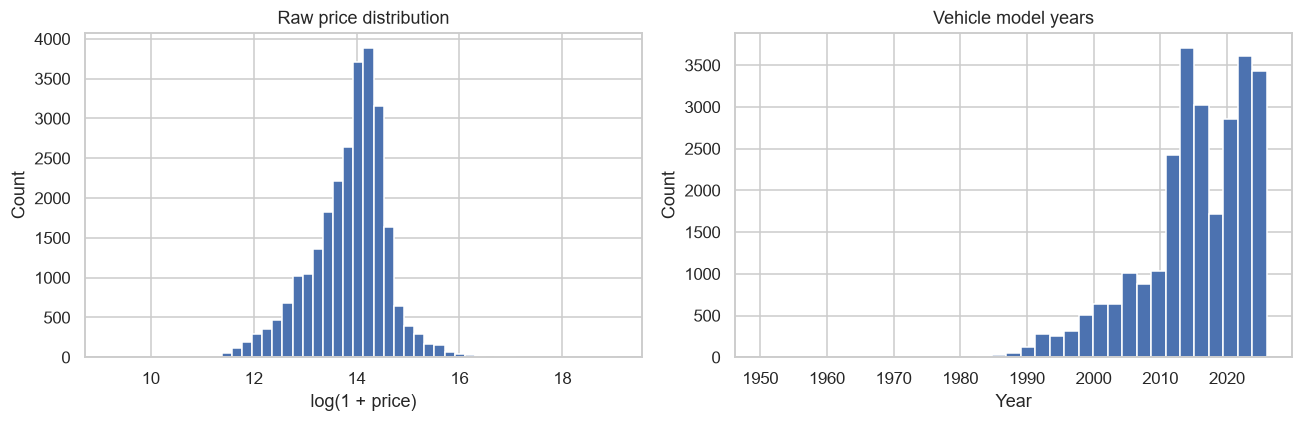

In [4]:
category_columns = df_raw.select_dtypes(include=["object", "string"]).columns
category_summary = pd.DataFrame({
    "unique_count": df_raw[category_columns].nunique(),
    "missing_count": df_raw[category_columns].isna().sum(),
    "top_freq": df_raw[category_columns].mode().iloc[0]
})
display(category_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log1p(df_raw["price_try"].dropna()), bins=50)
axes[0].set(title="Raw price distribution", xlabel="log(1 + price)", ylabel="Count")
axes[1].hist(df_raw["year"].dropna(), bins=35)
axes[1].set(title="Vehicle model years", xlabel="Year", ylabel="Count")
plt.tight_layout()
plt.show()

## 3. Inspect questionable values

Very large tramer values may come from extraction errors. A percentile cap alone
is not sufficient here: the raw 99th percentile is already around TRY 44 million.
The frequent small positive values also need source verification.
Tramer is inspected here to explain its exclusion; it is not a model input.

In [5]:
display(df_raw.nlargest(10, "tramer_tl")[[
    "brand", "series", "model", "price_try", "tramer_tl"
]])
display(df_raw["tramer_tl"].value_counts().head(12).to_frame("count"))
display(df_raw["tramer_tl"].quantile([0.50, 0.90, 0.95, 0.99, 1.00]).to_frame("tramer_try"))

price_review = df_raw.loc[
    ~df_raw["price_try"].between(MIN_PRICE, MAX_PRICE),
    ["brand", "series", "model", "year", "price_try"],
]
print(f"Rows outside the selected price range: {len(price_review):,}")
display(price_review.head(15))

Rows outside the selected price range: 63


,brand,series,model,price_try,tramer_tl
18300,Volkswagen,T-Cross,1.0 TSI Life,1649000,5542952290
19024,Hyundai,Tucson,1.6 CRDi Elite Plus,2215000,5428103278
24951,Ford,F,150,6900000,5332900132
25951,Ford,F,150,6900000,5332900132
19696,Kia,Sportage,1.6 CRDI Prestige,1595000,44721712
15644,Peugeot,3008,1.5 BlueHDI Active Prime Edition,1660000,44716522
15721,Peugeot,3008,1.5 BlueHDI Active Prime Edition,1660000,44716522
15652,Peugeot,e-3008,Allure,1960000,44715194
15730,Peugeot,e-3008,Allure,1960000,44715194
17742,Volkswagen,Tayron,1.5 e-TSI Life,2770000,44712639


,count
tramer_tl,
5,17780
0,3679
14,294
1,192
4,159
2,143
3,142
105,82
12,72


,tramer_try
0.50,5.00
0.90,"2,023.00"
0.95,"40,000.00"
0.99,"44,547,150.56"
1.00,"5,542,952,290.00"


,brand,series,model,year,price_try
303,Renault,R 12,TS,1977,77000
324,Renault,R 9,1.4 Broadway,1987,96500
2278,Fiat,Tempra,1.6 SX A,1993,189000000
2340,Fiat,Uno,70 S,1996,60000
2836,Fiat,Uno,60 S,1994,95000
3903,Opel,Corsa,1.6 GSi,1998,68350
3960,Opel,Vectra,1.6 GL,1992,57400
4261,Ford,Escort,1.6 CLX,1996,59000
4338,Ford,Taunus,1.6 S,1990,89000
4404,Ford,Festiva,1.3 GL,1994,80000


## 4. Basic cleaning

The part-condition columns are excluded because several are constant or contain
questionable counts. Their usefulness can be revisited after checking the source.
Missing numeric and categorical inputs are retained for the training pipeline.
No missing-value statistics are calculated from the full dataset.
Tramer is excluded before duplicate removal, together with the condition fields.
The raw CSV is kept unchanged. No damage amount is corrected or used to filter rows.

In [6]:
columns_to_drop = [
    "hood_damaged", "roof_damaged", "vehicle_condition",
    "local_painted_count", "changed_count", "painted_count",
    "roof_changed", "hood_changed", "hood_painted", "roof_painted",
    "original_count", "car_identity", "tramer_tl",
]

df_clean = df_raw.drop(columns=columns_to_drop, errors="ignore").copy()
cleaning_steps = []

for column in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[column] = df_clean[column].str.strip().replace(
        r"(?i)^\s*(?:-|--|none|null|n/a|nan)?\s*$", np.nan, regex=True
    )

numeric_columns = [
    "price_try", "year", "mileage_km", "engine_displacement_cc",
    "engine_power_hp",
]
for column in numeric_columns:
    df_clean[column] = pd.to_numeric(df_clean[column], errors="coerce")
df_clean[numeric_columns] = df_clean[numeric_columns].replace([np.inf, -np.inf], np.nan)

rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=["price_try", "brand", "series", "model"]).copy()
cleaning_steps.append({
    "step": "Remove missing target or vehicle identity",
    "affected_rows": rows_before - len(df_clean),
    "remaining_rows": len(df_clean),
})

rows_before = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
cleaning_steps.append({
    "step": "Remove duplicate rows after excluding unreliable columns",
    "affected_rows": rows_before - len(df_clean),
    "remaining_rows": len(df_clean),
})

# Keep only the selected price range. Do not guess a correction for a large price.
rows_before = len(df_clean)
df_clean = df_clean.loc[df_clean["price_try"].between(MIN_PRICE, MAX_PRICE)].copy()
cleaning_steps.append({
    "step": "Keep the selected price range",
    "affected_rows": rows_before - len(df_clean),
    "remaining_rows": len(df_clean),
})

## 5. Mileage, year, and engine checks

Negative mileage and obvious placeholder values become missing. Other high
mileages are retained: dividing them by ten without source evidence could change
a genuine observation. Non-positive engine values are also treated as missing.

In [7]:
invalid_mileage = df_clean["mileage_km"].lt(0) | df_clean["mileage_km"].isin(
    [999999, 999990, 1000000]
)
df_clean.loc[invalid_mileage, "mileage_km"] = np.nan
cleaning_steps.append({
    "step": "Mark invalid or placeholder mileage as missing",
    "affected_rows": int(invalid_mileage.sum()),
    "remaining_rows": len(df_clean),
})

invalid_year = (
    df_clean["year"].lt(1886)
    | df_clean["year"].gt(REFERENCE_YEAR + 1)
    | (df_clean["year"].notna() & df_clean["year"].mod(1).ne(0))
)
df_clean.loc[invalid_year, "year"] = np.nan
cleaning_steps.append({
    "step": "Mark invalid year as missing",
    "affected_rows": int(invalid_year.sum()),
    "remaining_rows": len(df_clean),
})

for column in ["engine_displacement_cc", "engine_power_hp"]:
    invalid_engine = df_clean[column].le(0)
    df_clean.loc[invalid_engine, column] = np.nan
    cleaning_steps.append({
        "step": f"Mark non-positive {column} as missing",
        "affected_rows": int(invalid_engine.sum()),
        "remaining_rows": len(df_clean),
    })

## 6. Cleaning summary and feature preparation

Vehicle age is a fixed transformation; it does not learn statistics from the
test data. Price is never used to modify an input feature.
The model does not account for damage history or vehicle condition.

In [8]:
rows_before = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
cleaning_steps.append({
    "step": "Remove duplicates created by the cleaning rules",
    "affected_rows": rows_before - len(df_clean),
    "remaining_rows": len(df_clean),
})
cleaning_report = pd.DataFrame(cleaning_steps)
display(cleaning_report)
print(f"Rows available for modelling: {len(df_clean):,}")

df_clean["vehicle_age"] = REFERENCE_YEAR - df_clean["year"]
display(df_clean.isna().sum().to_frame("missing_before_pipeline"))

Rows available for modelling: 25,080


,step,affected_rows,remaining_rows
0,Remove missing target or vehicle identity,19,26514
1,Remove duplicate rows after excluding unreliab...,1371,25143
2,Keep the selected price range,63,25080
3,Mark invalid or placeholder mileage as missing,4,25080
4,Mark invalid year as missing,0,25080
5,Mark non-positive engine_displacement_cc as mi...,0,25080
6,Mark non-positive engine_power_hp as missing,0,25080
7,Remove duplicates created by the cleaning rules,0,25080


,missing_before_pipeline
brand,0
series,0
model,0
transmission,8
fuel_type,0
body_type,33
color,3
drivetrain,264
price_try,0
year,0


## 7. Separate training and test data

Similar listings may appear more than once with different prices or tramer values.
Rows with identical basic vehicle attributes are therefore kept in the same group.
Grouping reduces one type of overlap; without listing IDs or VINs, it cannot prove
that every repeated physical vehicle has been identified.

In [9]:
group_columns = [
    "brand", "series", "model", "transmission", "fuel_type", "body_type",
    "color", "drivetrain", "year", "mileage_km",
    "engine_displacement_cc", "engine_power_hp",
]
groups = pd.util.hash_pandas_object(df_clean[group_columns], index=False)

X = df_clean.drop(columns=["price_try", "year"])
y = np.log1p(df_clean["price_try"])

splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_index, test_index = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_index].copy(), X.iloc[test_index].copy()
y_train, y_test = y.iloc[train_index].copy(), y.iloc[test_index].copy()
train_groups, test_groups = groups.iloc[train_index], groups.iloc[test_index]

assert set(train_groups).isdisjoint(set(test_groups))
assert X_train.index.intersection(X_test.index).empty
assert "price_try" not in X_train.columns
assert not any("tramer" in column.lower() for column in X_train.columns)

print(f"Training rows: {len(X_train):,}")
print(f"Test rows: {len(X_test):,}")
print(f"Actual test proportion: {len(X_test) / len(X):.2%}")
print("Shared vehicle groups between training and test: 0")
print("Damage history is excluded; no training rows are filtered by tramer.")

Training rows: 20,069
Test rows: 5,011
Actual test proportion: 19.98%
Shared vehicle groups between training and test: 0
Damage history is excluded; no training rows are filtered by tramer.


## 8. Preprocessing pipeline

Numeric inputs use training-fold medians. Categorical inputs use training-fold
modes and one-hot encoding. This simpler version uses global medians/modes within
each fold rather than a custom brand/model-based imputer.
The scaler is included for Ridge and Lasso. The same preprocessing is used for
every model to keep the comparison straightforward.

In [10]:
categorical_columns = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler(with_mean=False)),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns),
], sparse_threshold=1.0)

## 9. Models and evaluation metrics

The models learn log price. Predictions are converted back to TRY for MAE and
TRY-scale R². Log-scale R² is shown separately, so the two scales are not confused.
The median baseline shows how much is gained over a prediction with no features.

In [11]:
models = {
    "Median baseline": DummyRegressor(strategy="median"),
    "Ridge": Ridge(alpha=10),
    "Lasso": Lasso(alpha=0.001, max_iter=10_000),
    "XGBoost": XGBRegressor(
        objective="reg:squarederror", random_state=RANDOM_STATE,
        n_jobs=MODEL_THREADS, verbosity=0,
    ),
    "LightGBM": LGBMRegressor(
        random_state=RANDOM_STATE, n_jobs=MODEL_THREADS, verbose=-1,
    ),
    "CatBoost": CatBoostRegressor(
        loss_function="RMSE", random_state=RANDOM_STATE,
        thread_count=MODEL_THREADS, verbose=0, allow_writing_files=False,
    ),
}

def mae_in_try(actual_log, predicted_log):
    return mean_absolute_error(np.expm1(actual_log), np.expm1(predicted_log))

def r2_in_try(actual_log, predicted_log):
    return r2_score(np.expm1(actual_log), np.expm1(predicted_log))

## 10. Cross-validation on the training data

The test set is not used to select the model. The model with the lowest mean CV
MAE in TRY is selected. The same group folds are used for all models.
All training and validation rows from each split are retained. No feature or
row selection uses tramer.
CV R² is the average of the fold scores, not a single pooled prediction score.

In [12]:
cv = GroupKFold(n_splits=CV_FOLDS)
cv_splits = list(cv.split(X_train, y_train, train_groups))

for fold_train, fold_valid in cv_splits:
    assert set(train_groups.iloc[fold_train]).isdisjoint(set(train_groups.iloc[fold_valid]))

cv_rows = []
for model_name, model in models.items():
    print(f"Running cross-validation: {model_name}", flush=True)
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(model)),
    ])
    fold_mae, fold_r2_try, fold_r2_log = [], [], []
    for fold_train, fold_valid in cv_splits:
        fold_pipeline = clone(pipeline)
        fold_pipeline.fit(X_train.iloc[fold_train], y_train.iloc[fold_train])
        predicted_log = fold_pipeline.predict(X_train.iloc[fold_valid])
        actual_log = y_train.iloc[fold_valid]
        fold_mae.append(mae_in_try(actual_log, predicted_log))
        fold_r2_try.append(r2_in_try(actual_log, predicted_log))
        fold_r2_log.append(r2_score(actual_log, predicted_log))
    cv_rows.append({
        "Model": model_name,
        "CV MAE (TRY)": np.mean(fold_mae),
        "CV MAE std (TRY)": np.std(fold_mae, ddof=1),
        "CV R2 (TRY)": np.mean(fold_r2_try),
        "CV R2 (log)": np.mean(fold_r2_log),
    })

cv_results = pd.DataFrame(cv_rows).sort_values("CV MAE (TRY)").reset_index(drop=True)
best_model_name = cv_results.loc[0, "Model"]
display(cv_results.style.format({
    "CV MAE (TRY)": "{:,.2f}",
    "CV MAE std (TRY)": "{:,.2f}",
    "CV R2 (TRY)": "{:.6f}",
    "CV R2 (log)": "{:.6f}",
}))
print(f"Model selected using CV MAE: {best_model_name}")

Running cross-validation: Median baseline
Running cross-validation: Ridge
Running cross-validation: Lasso
Running cross-validation: XGBoost
Running cross-validation: LightGBM
Running cross-validation: CatBoost
Model selected using CV MAE: CatBoost


,Model,CV MAE (TRY),CV MAE std (TRY),CV R2 (TRY),CV R2 (log)
0,CatBoost,"134,450.98","1,974.57",0.936122,0.956966
1,XGBoost,"141,665.71","1,974.53",0.919518,0.950807
2,LightGBM,"143,305.92","3,132.84",0.922910,0.951406
3,Ridge,"151,510.90","7,133.29",0.850902,0.946955
4,Lasso,"220,172.32","9,591.84",0.759395,0.917828
5,Median baseline,"682,786.79","7,829.15",-0.018506,-0.026526


## 11. Evaluate on the held-out test set

All models exclude damage-history features and fit on the full training split.
All test rows are evaluated. The CV-selected model stays selected.
Further tuning based on these scores requires another independent evaluation set.

In [13]:
fitted_models = {}
test_predictions = {}
test_rows = []
actual_try = np.expm1(y_test)

for model_name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(model)),
    ])
    pipeline.fit(X_train, y_train)
    predicted_log = pipeline.predict(X_test)
    predicted_try = np.expm1(predicted_log)
    assert np.isfinite(predicted_try).all()

    fitted_models[model_name] = pipeline
    test_predictions[model_name] = predicted_try
    test_rows.append({
        "Model": model_name,
        "Test MAE (TRY)": mean_absolute_error(actual_try, predicted_try),
        "Test RMSE (TRY)": root_mean_squared_error(actual_try, predicted_try),
        "Test R2 (TRY)": r2_score(actual_try, predicted_try),
        "Test R2 (log)": r2_score(y_test, predicted_log),
    })

model_comparison = cv_results.merge(pd.DataFrame(test_rows), on="Model")
display(model_comparison.style.format({
    column: "{:.6f}" if "R2" in column else "{:,.2f}"
    for column in model_comparison.columns if column != "Model"
}))

best_model = fitted_models[best_model_name]
selected_result = model_comparison.loc[model_comparison["Model"] == best_model_name].iloc[0]
print(f"Selected model: {best_model_name}")
print(f"Test R2 (TRY): {selected_result['Test R2 (TRY)']:.6f}")
print(f"Test MAE (TRY): {selected_result['Test MAE (TRY)']:,.2f}")

Selected model: CatBoost
Test R2 (TRY): 0.958941
Test MAE (TRY): 128,154.94


,Model,CV MAE (TRY),CV MAE std (TRY),CV R2 (TRY),CV R2 (log),Test MAE (TRY),Test RMSE (TRY),Test R2 (TRY),Test R2 (log)
0,CatBoost,"134,450.98","1,974.57",0.936122,0.956966,"128,154.94","293,528.55",0.958941,0.958653
1,XGBoost,"141,665.71","1,974.53",0.919518,0.950807,"136,374.51","315,408.19",0.952591,0.954166
2,LightGBM,"143,305.92","3,132.84",0.922910,0.951406,"138,118.84","335,300.37",0.946423,0.955258
3,Ridge,"151,510.90","7,133.29",0.850902,0.946955,"149,390.11","577,448.15",0.841095,0.952268
4,Lasso,"220,172.32","9,591.84",0.759395,0.917828,"223,371.68","745,724.90",0.734986,0.919899
5,Median baseline,"682,786.79","7,829.15",-0.018506,-0.026526,"691,303.24","1,462,957.55",-0.019940,-0.020493


## 12. Inspect prediction errors

R² alone can hide large errors on individual cars. Inspect the largest errors and
compare typical percentage errors across price bands.

In [14]:
prediction_review = df_clean.loc[X_test.index, [
    "brand", "series", "model", "year", "mileage_km"
]].copy()
prediction_review["actual_price_try"] = actual_try
prediction_review["predicted_price_try"] = test_predictions[best_model_name]
prediction_review["residual_try"] = (
    prediction_review["actual_price_try"] - prediction_review["predicted_price_try"]
)
prediction_review["absolute_error_try"] = prediction_review["residual_try"].abs()
prediction_review["absolute_pct_error"] = (
    prediction_review["absolute_error_try"] / prediction_review["actual_price_try"] * 100
)
display(prediction_review.nlargest(10, "absolute_error_try"))

price_bands = pd.cut(
    prediction_review["actual_price_try"],
    bins=[0, 500_000, 1_000_000, 2_000_000, 5_000_000, np.inf],
)
error_by_price = prediction_review.groupby(price_bands, observed=True).agg(
    count=("absolute_error_try", "size"),
    mae_try=("absolute_error_try", "mean"),
    median_absolute_pct_error=("absolute_pct_error", "median"),
)
display(error_by_price)

,brand,series,model,year,mileage_km,actual_price_try,predicted_price_try,residual_try,absolute_error_try,absolute_pct_error
22750,Land Rover,Range Rover Sport,3.0 Autobiography,"2,024.00","36,980.00","26,250,000.00","19,173,906.02","7,076,093.98","7,076,093.98",26.96
14182,Kia,Rio,1.4 CRDi Fancy,"2,012.00","179,000.00","6,800,000.00","653,816.21","6,146,183.79","6,146,183.79",90.39
6710,BMW,3 Serisi,325Ci,"1,984.00","200,000.00","1,099,000.00","5,212,259.93","-4,113,259.93","4,113,259.93",374.27
24957,Ford,F,150,"2,023.00","9,050.00","6,300,000.00","10,350,404.82","-4,050,404.82","4,050,404.82",64.29
11047,Audi,A8,4.0 TFSI Quattro,"2,021.00","42,590.00","16,850,000.00","13,063,324.26","3,786,675.74","3,786,675.74",22.47
24951,Ford,F,150,"2,023.00","6,001.00","6,900,000.00","10,604,572.66","-3,704,572.66","3,704,572.66",53.69
23374,Land Rover,Defender,110 2.0 X-Dynamic HSE,"2,025.00","14,700.00","13,200,000.00","9,591,051.49","3,608,948.51","3,608,948.51",27.34
6536,BMW,M Serisi,M3 Competition,"2,020.00","45,000.00","6,500,000.00","3,175,223.75","3,324,776.25","3,324,776.25",51.15
22844,Land Rover,Range Rover,3.0 SDV6 Hybrid Autobiography,"2,020.00","107,000.00","8,719,950.00","5,683,541.74","3,036,408.26","3,036,408.26",34.82
23225,Land Rover,Range Rover,3.0 SDV6 Hybrid Autobiography,"2,020.00","182,834.00","9,745,000.00","6,919,548.93","2,825,451.07","2,825,451.07",28.99


,count,mae_try,median_absolute_pct_error
actual_price_try,,,
"(0.0, 500000.0]",788,"55,382.18",13.20
"(500000.0, 1000000.0]",1269,"81,581.71",8.22
"(1000000.0, 2000000.0]",2241,"106,584.67",5.68
"(2000000.0, 5000000.0]",640,"256,240.76",6.82
"(5000000.0, inf]",73,"1,262,544.40",9.33


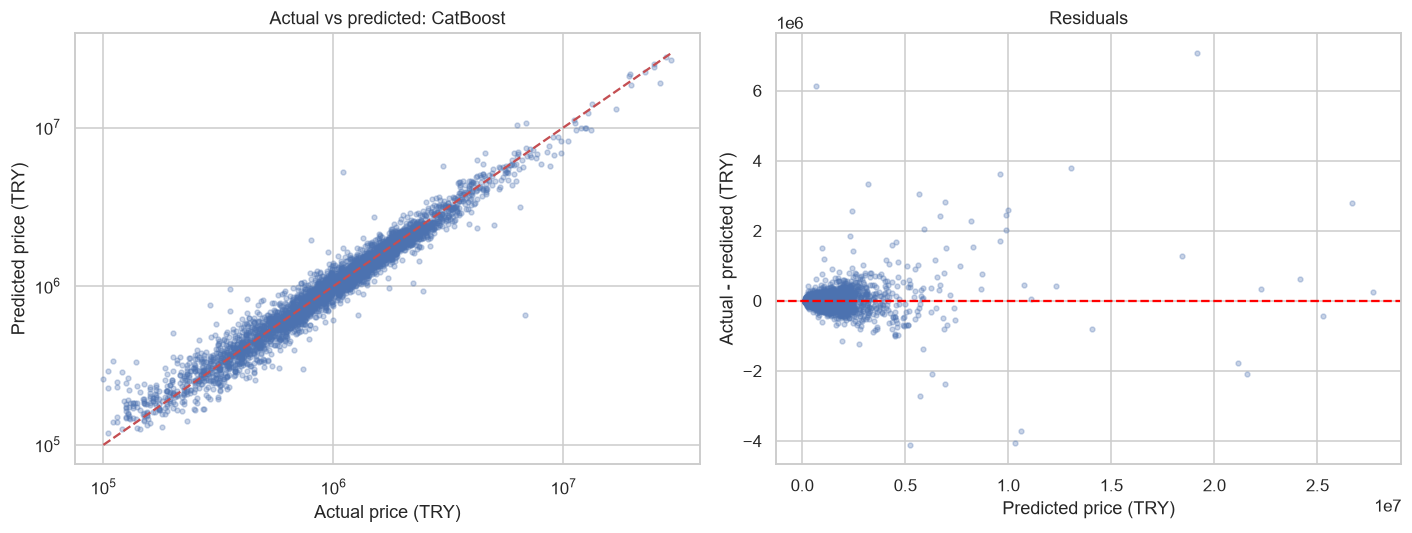

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
predicted = prediction_review["predicted_price_try"]
actual = prediction_review["actual_price_try"]
axes[0].scatter(actual, predicted, s=10, alpha=0.3)
lower = max(1, min(actual.min(), predicted.min()))
upper = max(actual.max(), predicted.max())
axes[0].plot([lower, upper], [lower, upper], "r--")
axes[0].set(
    xscale="log", yscale="log", xlabel="Actual price (TRY)",
    ylabel="Predicted price (TRY)", title=f"Actual vs predicted: {best_model_name}",
)
axes[1].scatter(predicted, prediction_review["residual_try"], s=10, alpha=0.3)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Predicted price (TRY)", ylabel="Actual - predicted (TRY)", title="Residuals")
plt.tight_layout()
plt.show()

## 13. Predict a prepared example row

This example uses a row that has already passed through the cleaning and feature
preparation cells. Raw external data needs the same steps before prediction.

In [16]:
example_car = X_test.iloc[[0]].copy()
example_prediction = np.expm1(best_model.predict(example_car))[0]
display(example_car)
print(f"Predicted price (TRY): {example_prediction:,.2f}")
print(f"Actual price (TRY): {np.expm1(y_test.iloc[0]):,.2f}")

Predicted price (TRY): 556,299.83
Actual price (TRY): 444,000.00


,brand,series,model,transmission,fuel_type,body_type,color,drivetrain,mileage_km,engine_displacement_cc,engine_power_hp,vehicle_age
1,Renault,Clio,1.2 Joy,Düz,Benzin,"Hatchback/5, 5 Koltuk",Siyah,Önden Çekiş,"224,000.00","1,149.00",75.00,13.00


## 14. Save results

car_dataset_cleaned.csv contains the cleaned training subset only. The prepared
full dataset and unfiltered held-out test subset are exported separately.
Missing-input replacements belong to the model pipeline, not the full dataset.

In [17]:
OUTPUT_DIR.mkdir(exist_ok=True)
cleaning_report.to_csv(OUTPUT_DIR / "cleaning_report.csv", index=False)
df_clean.loc[X_train.index].to_csv(OUTPUT_DIR / "car_dataset_cleaned.csv", index_label="source_row")

df_clean.to_csv(OUTPUT_DIR / "car_dataset_prepared.csv", index_label="source_row")
df_clean.loc[X_test.index].to_csv(OUTPUT_DIR / "car_dataset_test.csv", index_label="source_row")
model_comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
prediction_review.to_csv(OUTPUT_DIR / "test_predictions.csv", index_label="source_row")
error_by_price.to_csv(OUTPUT_DIR / "error_by_price.csv")

settings = {
    "random_state": RANDOM_STATE,
    "reference_year": REFERENCE_YEAR,
    "test_size": TEST_SIZE,
    "cv_folds": CV_FOLDS,
    "min_price": MIN_PRICE,
    "max_price": MAX_PRICE,
    "main_models_use_tramer": False,
    "damage_history_used": False,
    "tramer_rows_removed": False,
    "selected_model": best_model_name,
}
with (OUTPUT_DIR / "settings.json").open("w", encoding="utf-8") as file:
    json.dump(settings, file, indent=2)
print(f"Results saved to: {OUTPUT_DIR.resolve()}")

Results saved to: C:\Users\ghost\OneDrive\Desktop\projects\car-project-2\1 - data cleaning\outputs_car_price_simple


## 15. Findings and limitations

- Use the displayed CV and test tables to compare the models on both price scales.
- Tramer and other damage-history fields are excluded because their quality is unverified.
- No row is removed based on its tramer amount. The original CSV is unchanged.
- Estimates do not account for damage history or actual vehicle condition.
- The fixed price range limits which vehicles these results describe.
- Attribute groups reduce duplicate overlap but do not replace real vehicle IDs.
- No listing date is available, so this split does not measure future-market performance.
- Hyperparameters have not been tuned. The one-hot preprocessing is a simple shared
  baseline, rather than a separate optimized setup for every tree model.
- This is an analysis notebook, not a deployed prediction service.